## Uncoupled System

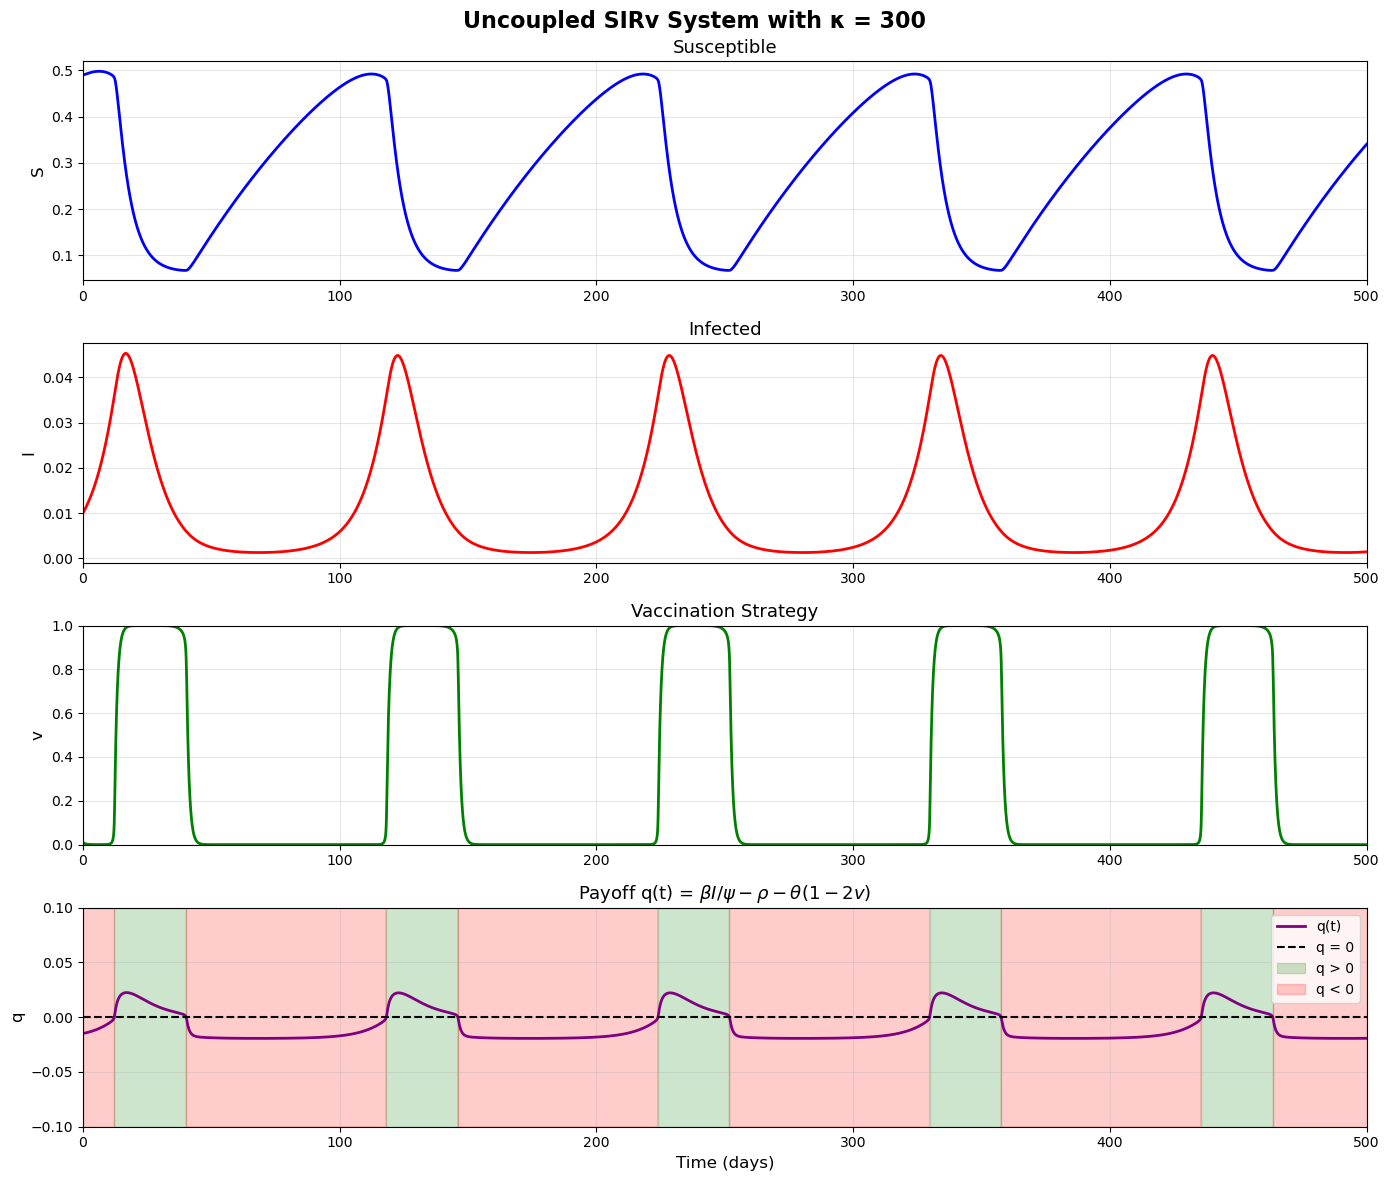

SIMULATION RESULTS (κ = 1000)

Final values at t = 500.0 days:
S = 0.340543
I = 0.001456
v = 0.000000
q = -0.01927185

PAYOFF q STATISTICS
Mean q: -0.00871250
Min q: -0.01935151
Max q: 0.02245992
Std q: 0.01395721
Fraction of time q > 0: 0.2788
Fraction of time q < 0: 0.7212


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

def uncoupled_smooth_sirv(t, y, alpha, beta, gamma, eta, theta, kappa, rho):
    """
    Uncoupled smooth SIRv system (epsilon = 0)
    y = [S, I, v]
    """
    S, I, v = y
    
    dS = alpha*(1 - S - I) - beta*S*(I) - eta*v*S
    dI = -gamma*I + beta*S*(I)
    dv = -v + 1/(1 + np.exp(-kappa*(beta*I - rho - theta*(1 - 2*v))))
    
    return [dS, dI, dv]

# Parameters
params = {
    'alpha': 0.01,
    'beta': 0.5,
    'gamma': 1/7,
    'eta': 1/7,
    'theta': 0.01,
    'kappa': 1000,  # Changed from 1000 to 100
    'rho': 0.01,
}

# Initial conditions: [S0, I0, v0]
y0 = [0.49, 0.01, 0.01]

# Time span
t_span = (0, 500)
t_eval = np.linspace(t_span[0], t_span[1], 5000)

# Solve the system
sol = solve_ivp(
    uncoupled_smooth_sirv,
    t_span,
    y0,
    args=(params['alpha'], params['beta'], params['gamma'], params['eta'],
          params['theta'], params['kappa'], params['rho']),
    t_eval=t_eval,
    method='LSODA',
    rtol=1e-8,
    atol=1e-10
)

S, I, v = sol.y

# Calculate payoff q(t)
q_t = params['beta']*(I) - params['rho'] - params['theta']*(1 - 2*v)

# Create plots
fig, axes = plt.subplots(4, 1, figsize=(14, 12))
fig.suptitle(r'Uncoupled SIRv System with κ = 300', fontsize=16, fontweight='bold')

# Plot S
axes[0].plot(sol.t, S, 'b-', linewidth=2)
axes[0].set_ylabel('S', fontsize=12)
axes[0].set_title('Susceptible', fontsize=13)
axes[0].grid(True, alpha=0.3)
axes[0].set_xlim(0, 500)

# Plot I
axes[1].plot(sol.t, I, 'r-', linewidth=2)
axes[1].set_ylabel('I', fontsize=12)
axes[1].set_title('Infected', fontsize=13)
axes[1].grid(True, alpha=0.3)
axes[1].set_xlim(0, 500)

# Plot v
axes[2].plot(sol.t, v, 'g-', linewidth=2)
axes[2].set_ylabel('v', fontsize=12)
axes[2].set_title('Vaccination Strategy', fontsize=13)
axes[2].set_ylim([0, 1])
axes[2].grid(True, alpha=0.3)
axes[2].set_xlim(0, 500)

# Plot q(t)
axes[3].plot(sol.t, q_t, 'purple', linewidth=2, label='q(t)')
axes[3].axhline(y=0, color='k', linestyle='--', linewidth=1.5, label='q = 0')
axes[3].fill_between(sol.t, -0.1, 0.1, where=(q_t >= 0), 
                     alpha=0.2, color='green', label='q > 0')
axes[3].fill_between(sol.t, -0.1, 0.1, where=(q_t < 0), 
                     alpha=0.2, color='red', label='q < 0')
axes[3].set_ylabel('q', fontsize=12)
axes[3].set_xlabel('Time (days)', fontsize=12)
axes[3].set_title(r'Payoff q(t) = $\beta I/\psi - \rho - \theta(1-2v)$', fontsize=13)
axes[3].set_ylim(-0.1, 0.1)
axes[3].set_xlim(0, 500)
axes[3].legend(fontsize=10, loc='best')
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print statistics
print("="*80)
print(f"SIMULATION RESULTS (κ = {params['kappa']})")
print("="*80)
print(f"\nFinal values at t = {sol.t[-1]:.1f} days:")
print(f"S = {S[-1]:.6f}")
print(f"I = {I[-1]:.6f}")
print(f"v = {v[-1]:.6f}")
print(f"q = {q_t[-1]:.8f}")

print("\n" + "="*80)
print("PAYOFF q STATISTICS")
print("="*80)
print(f"Mean q: {np.mean(q_t):.8f}")
print(f"Min q: {np.min(q_t):.8f}")
print(f"Max q: {np.max(q_t):.8f}")
print(f"Std q: {np.std(q_t):.8f}")
print(f"Fraction of time q > 0: {np.sum(q_t > 0) / len(q_t):.4f}")
print(f"Fraction of time q < 0: {np.sum(q_t < 0) / len(q_t):.4f}")

## Simulate the coupled system to check synchronization

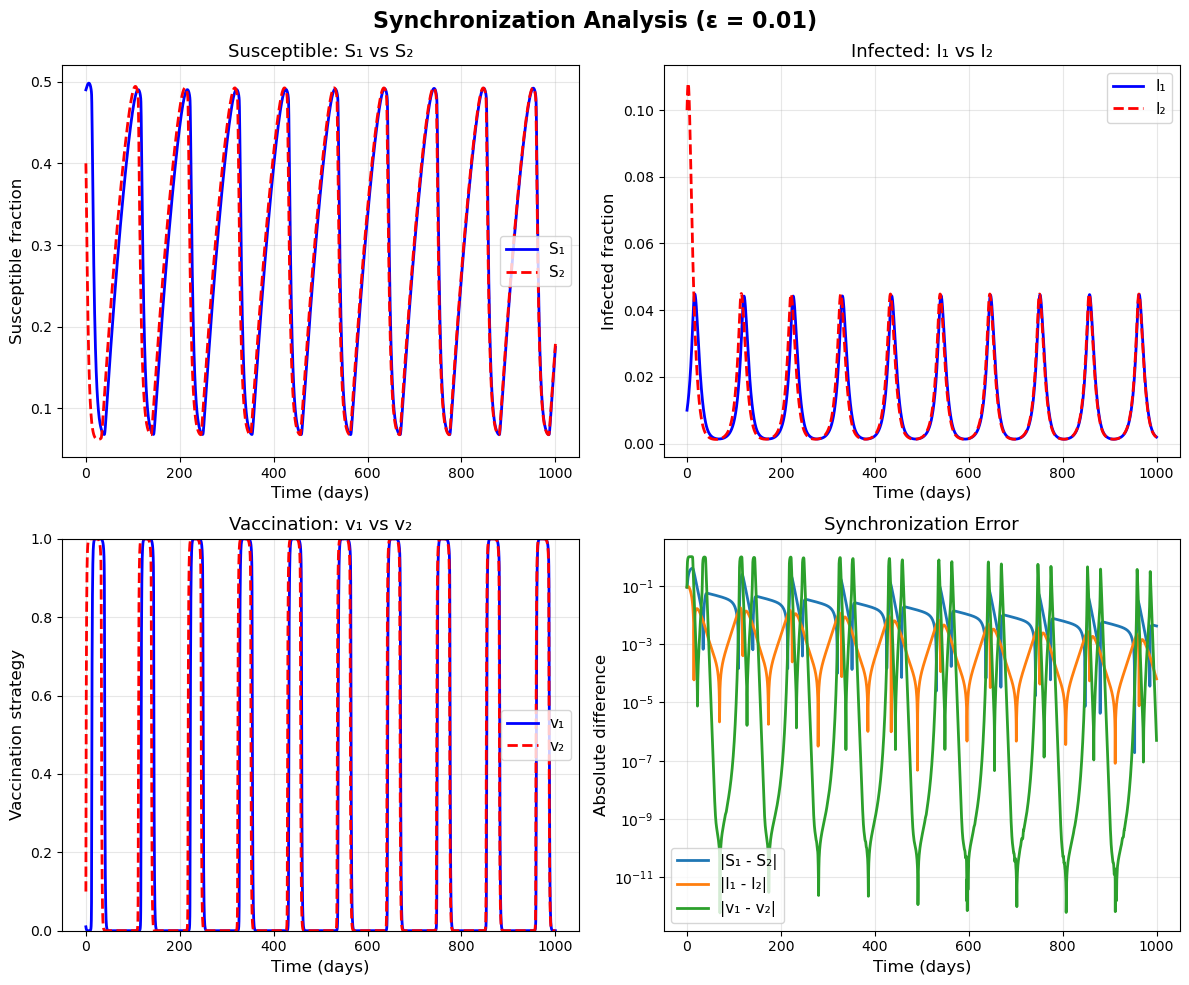


Synchronization Analysis at t = 1000.0 days:
Final |S₁ - S₂| = 0.004191
Final |I₁ - I₂| = 0.000064
Final |v₁ - v₂| = 0.000000

Mean absolute differences over time:
Mean |S₁ - S₂| = 0.026375
Mean |I₁ - I₂| = 0.003028
Mean |v₁ - v₂| = 0.060397


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Define the coupled system
def coupled_sirv(t, y, alpha, beta, gamma, epsilon, eta, theta, kappa, rho):
    """
    Coupled SIRv system with social influence
    y = [S1, I1, v1, S2, I2, v2]
    """
    S1, I1, v1, S2, I2, v2 = y
    
    # Group 1 dynamics
    dS1 = alpha*(1 - S1 - I1) - beta*S1*(I1) - eta*v1*S1
    dI1 = -gamma*I1 + beta*S1*(I1)
    dv1 = -v1 + 1/(1 + np.exp(-kappa*(beta*I1 - rho - theta*(1 - 2*((1-epsilon)*v1 + epsilon*v2)))))
    
    # Group 2 dynamics
    dS2 = alpha*(1 - S2 - I2) - beta*S2*(I2) - eta*v2*S2
    dI2 = -gamma*I2 + beta*S2*(I2)
    dv2 = -v2 + 1/(1 + np.exp(-kappa*(beta*I2 - rho - theta*(1 - 2*((1-epsilon)*v2 + epsilon*v1)))))
    
    return [dS1, dI1, dv1, dS2, dI2, dv2]

# Default parameters
params = {
    'alpha': 0.01,      # 1/day - loss of immunity
    'beta': 0.5,        # 1/day - transmission rate
    'gamma': 1/7,       # 1/day - recovery rate
    'epsilon': 0.01,     # coupling parameter (you can adjust this)
    'eta': 1/7,         # 1/day - vaccination appointment rate
    'theta': 0.01,      # relational cost
    'kappa': 1000,      # payoff sensitivity
    'rho': 0.01,        # risk of vaccine morbidity
}

# Initial conditions: (S1, I1, v1, S2, I2, v2)
y0 = [0.49, 0.01, 0.01, 0.4, 0.1, 0.1]

# Time span
t_span = (0, 1000)  # days
t_eval = np.linspace(t_span[0], t_span[1], 5000)

# Solve the system
sol = solve_ivp(
    coupled_sirv, 
    t_span, 
    y0, 
    args=(params['alpha'], params['beta'], params['gamma'], params['epsilon'], 
          params['eta'], params['theta'], params['kappa'], params['rho']),
    t_eval=t_eval,
    method='LSODA',
    rtol=1e-8,
    atol=1e-10
)

# Extract solutions
S1, I1, v1, S2, I2, v2 = sol.y

# Create synchronization comparison plots
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle(f'Synchronization Analysis (ε = {params["epsilon"]})', fontsize=16, fontweight='bold')

# S1 vs S2
axes[0, 0].plot(sol.t, S1, 'b-', label='S₁', linewidth=2)
axes[0, 0].plot(sol.t, S2, 'r--', label='S₂', linewidth=2)
axes[0, 0].set_xlabel('Time (days)', fontsize=12)
axes[0, 0].set_ylabel('Susceptible fraction', fontsize=12)
axes[0, 0].set_title('Susceptible: S₁ vs S₂', fontsize=13)
axes[0, 0].legend(fontsize=11)
axes[0, 0].grid(True, alpha=0.3)

# I1 vs I2
axes[0, 1].plot(sol.t, I1, 'b-', label='I₁', linewidth=2)
axes[0, 1].plot(sol.t, I2, 'r--', label='I₂', linewidth=2)
axes[0, 1].set_xlabel('Time (days)', fontsize=12)
axes[0, 1].set_ylabel('Infected fraction', fontsize=12)
axes[0, 1].set_title('Infected: I₁ vs I₂', fontsize=13)
axes[0, 1].legend(fontsize=11)
axes[0, 1].grid(True, alpha=0.3)

# v1 vs v2
axes[1, 0].plot(sol.t, v1, 'b-', label='v₁', linewidth=2)
axes[1, 0].plot(sol.t, v2, 'r--', label='v₂', linewidth=2)
axes[1, 0].set_xlabel('Time (days)', fontsize=12)
axes[1, 0].set_ylabel('Vaccination strategy', fontsize=12)
axes[1, 0].set_title('Vaccination: v₁ vs v₂', fontsize=13)
axes[1, 0].legend(fontsize=11)
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].set_ylim([0, 1])

# Difference measures
axes[1, 1].plot(sol.t, np.abs(S1 - S2), label='|S₁ - S₂|', linewidth=2)
axes[1, 1].plot(sol.t, np.abs(I1 - I2), label='|I₁ - I₂|', linewidth=2)
axes[1, 1].plot(sol.t, np.abs(v1 - v2), label='|v₁ - v₂|', linewidth=2)
axes[1, 1].set_xlabel('Time (days)', fontsize=12)
axes[1, 1].set_ylabel('Absolute difference', fontsize=12)
axes[1, 1].set_title('Synchronization Error', fontsize=13)
axes[1, 1].legend(fontsize=11)
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].set_yscale('log')

plt.tight_layout()
plt.show()

# Print synchronization metrics
print(f"\nSynchronization Analysis at t = {sol.t[-1]:.1f} days:")
print(f"Final |S₁ - S₂| = {abs(S1[-1] - S2[-1]):.6f}")
print(f"Final |I₁ - I₂| = {abs(I1[-1] - I2[-1]):.6f}")
print(f"Final |v₁ - v₂| = {abs(v1[-1] - v2[-1]):.6f}")
print(f"\nMean absolute differences over time:")
print(f"Mean |S₁ - S₂| = {np.mean(np.abs(S1 - S2)):.6f}")
print(f"Mean |I₁ - I₂| = {np.mean(np.abs(I1 - I2)):.6f}")
print(f"Mean |v₁ - v₂| = {np.mean(np.abs(v1 - v2)):.6f}")

## Calculate $H(\phi)$

State after transients: S=0.204101, I=0.004105, v=0.004847
Period T = 86.910000 days
Computed gamma'(t) = F(gamma(t)) along the limit cycle

Integrating adjoint equation for 50 periods
Total integration time: 4345.50 days
Backward integration complete
Solution shape: (3, 500000)
Z_raw shape after extracting last period: (3, 10000)

Period T = 86.910000
Angular frequency omega = 2*pi/T = 0.072295

Before normalization:
  Z . gamma' ranges from 6.442753e-03 to 6.517575e-03

After normalization:
  Z . gamma' should equal 2*pi/T = 0.072295
  Z . gamma' ranges from 0.072295 to 0.072295

PERIODICITY CHECK

Z(0) = [-1.931592, -44.421112, 0.057810]
Z(T) = [-1.931594, -44.343234, 0.057930]

Z(T) - Z(0) = [-1.929432e-06, 7.787827e-02, 1.198256e-04]
|Z(T) - Z(0)| = 7.787836e-02
Z is NOT periodic -- may need more periods!
Computed sigma'(xi(t)) along the limit cycle
  sigma' ranges from 4.099675e-03 to 2.499998e-01
Created periodic interpolation for v(t)

Computed H(phi) at 200 points
  H ranges f

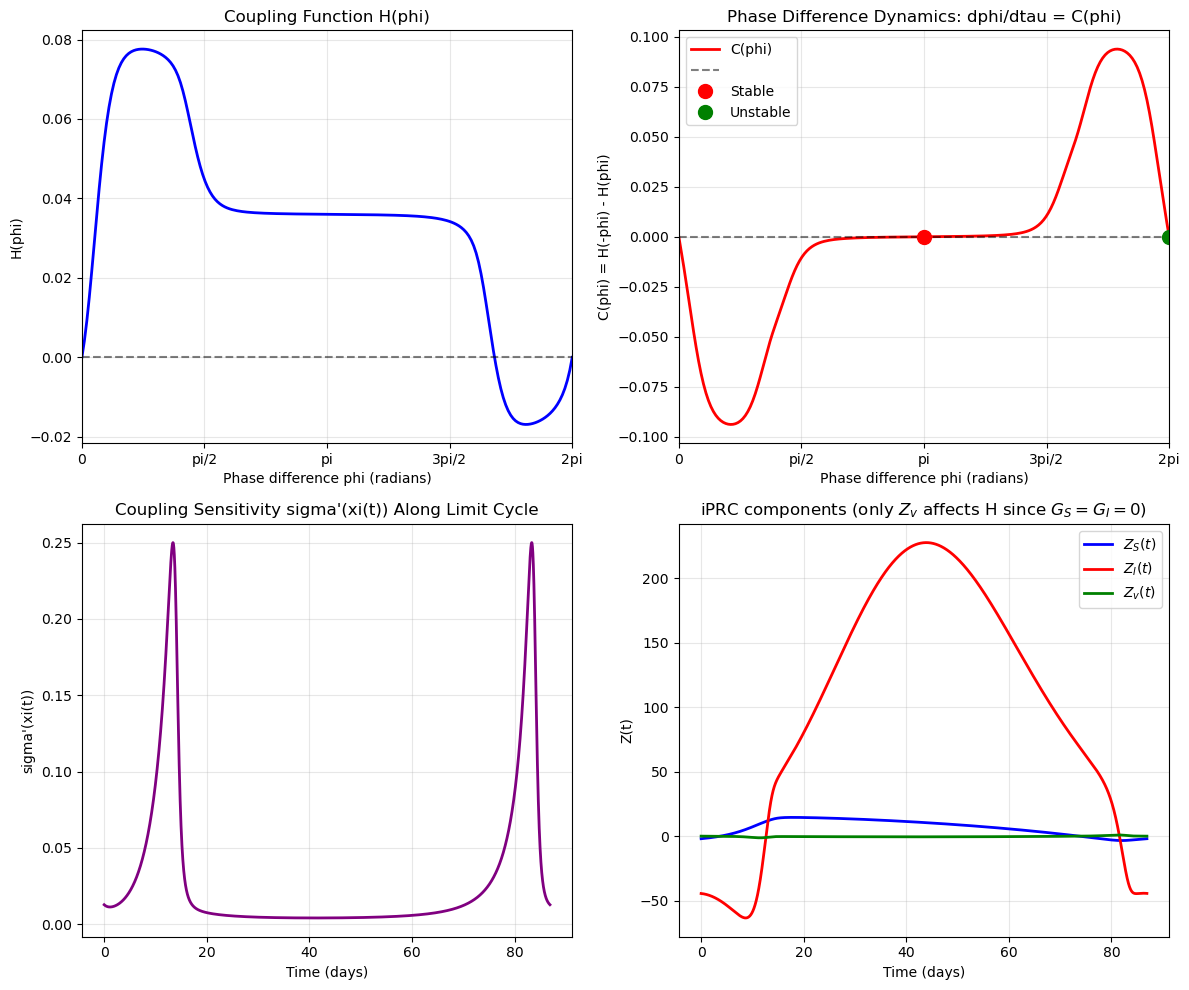


SUMMARY
Period T = 86.9100 days
omega = 2*pi/T = 0.072295 rad/day
phi is in radians; C'(phi) is therefore a rate in day^-1

Coupling function H(phi) computed
Phase dynamics: dphi/dtau = H(-phi) - H(phi) = C(phi)

Phase-locked states occur where C(phi) = 0
  - Stable if C'(phi) < 0 (green dots)
  - Unstable if C'(phi) > 0 (red dots)


In [1]:
"""
Find the limit cycle (periodic orbit) for the uncoupled smooth SIRv system.

This script:
1. Integrates the system for a long time to reach the attractor
2. Detects the period using Poincare section crossings
3. Extracts one complete cycle gamma(t) = [S(t), I(t), v(t)]
4. Verifies periodicity
"""

import numpy as np
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt


# =============================================================================
# SYSTEM DEFINITION
# =============================================================================

def uncoupled_smooth_sirv(t, y, params):
    """
    Uncoupled smooth SIRv system (epsilon = 0)
    y = [S, I, v]
    """
    S, I, v = y
    alpha = params['alpha']
    beta = params['beta']
    gamma = params['gamma']
    eta = params['eta']
    theta = params['theta']
    kappa = params['kappa']
    rho = params['rho']

    dS = alpha*(1 - S - I) - beta*S*I - eta*v*S
    dI = -gamma*I + beta*S*I
    dv = -v + 1/(1 + np.exp(-kappa*(beta*I - rho - theta*(1 - 2*v))))

    return [dS, dI, dv]


# =============================================================================
# PARAMETERS
# =============================================================================

params = {
    'alpha': 0.01,
    'beta': 0.5,
    'gamma': 1/7,
    'eta': 1/7,
    'theta': 0.01,
    'kappa': 300,
    'rho': 0.01,
}

y0 = [0.49, 0.01, 0.01]  # Initial conditions [S0, I0, v0]


# =============================================================================
# STEP 1: INTEGRATE PAST TRANSIENTS
# =============================================================================

t_transient = 5000

sol_transient = solve_ivp(
    lambda t, y: uncoupled_smooth_sirv(t, y, params),
    [0, t_transient],
    y0,
    method='RK45',
    rtol=1e-10,
    atol=1e-12
)

y_after_transient = sol_transient.y[:, -1]
print(f"State after transients: S={y_after_transient[0]:.6f}, "
      f"I={y_after_transient[1]:.6f}, v={y_after_transient[2]:.6f}")


# =============================================================================
# STEP 2: FIND THE PERIOD
# =============================================================================

t_cycle_search = 2000
dt = 0.01
t_eval = np.arange(0, t_cycle_search, dt)

sol_search = solve_ivp(
    lambda t, y: uncoupled_smooth_sirv(t, y, params),
    [0, t_cycle_search],
    y_after_transient,
    method='RK45',
    t_eval=t_eval,
    rtol=1e-10,
    atol=1e-12
)

# Find peaks in I to determine period
I_data = sol_search.y[1, :]
peaks, _ = find_peaks(I_data, height=np.mean(I_data), distance=int(1/dt))

peak_times = sol_search.t[peaks]
periods = np.diff(peak_times)
T = np.mean(periods[-5:])  # Average of last 5 periods

print(f"Period T = {T:.6f} days")


# =============================================================================
# STEP 3: EXTRACT ONE COMPLETE CYCLE
# =============================================================================

# Start from a peak (phase = 0 at peak I)
start_idx = peaks[-2]
y_cycle_start = sol_search.y[:, start_idx]

# Integrate for exactly one period
n_points = 10000
t_cycle = np.linspace(0, T, n_points)

sol_cycle = solve_ivp(
    lambda t, y: uncoupled_smooth_sirv(t, y, params),
    [0, T],
    y_cycle_start,
    method='RK45',
    t_eval=t_cycle,
    rtol=1e-12,
    atol=1e-14
)


# =============================================================================
# STEP 4: STORE THE LIMIT CYCLE AS Gamma
# =============================================================================

class Gamma:
    """
    Container for the limit cycle gamma(t) = [S(t), I(t), v(t)]

    Usage:
        Gamma.t    - time array [0, T]
        Gamma.S    - S(t) along the cycle
        Gamma.I    - I(t) along the cycle
        Gamma.v    - v(t) along the cycle
        Gamma.T    - period
        Gamma.y    - full state array, shape (3, n_points)
    """
    t = sol_cycle.t
    S = sol_cycle.y[0, :]
    I = sol_cycle.y[1, :]
    v = sol_cycle.y[2, :]
    T = T
    y = sol_cycle.y  # [S, I, v] stacked


# =============================================================================
# COMPUTE THE JACOBIAN DF USING SYMPY
# =============================================================================

import sympy as sp

# Define symbolic variables
S_sym, I_sym, v_sym = sp.symbols('S I v')
alpha_sym, beta_sym, gamma_sym, eta_sym = sp.symbols('alpha beta gamma eta')
theta_sym, kappa_sym, rho_sym = sp.symbols('theta kappa rho')

# Define the vector field F = [F1, F2, F3]
F1 = alpha_sym*(1 - S_sym - I_sym) - beta_sym*S_sym*I_sym - eta_sym*v_sym*S_sym
F2 = -gamma_sym*I_sym + beta_sym*S_sym*I_sym
F3 = -v_sym + 1/(1 + sp.exp(-kappa_sym*(beta_sym*I_sym - rho_sym
                                        - theta_sym*(1 - 2*v_sym))))

F = sp.Matrix([F1, F2, F3])
state = sp.Matrix([S_sym, I_sym, v_sym])

# Compute Jacobian symbolically
DF_symbolic = F.jacobian(state)

# Convert to numerical function
param_symbols = (alpha_sym, beta_sym, gamma_sym, eta_sym,
                 theta_sym, kappa_sym, rho_sym)
all_symbols = (S_sym, I_sym, v_sym) + param_symbols

DF_func = sp.lambdify(all_symbols, DF_symbolic, modules='numpy')


def compute_DF(S, I, v, params):
    """
    Compute the Jacobian matrix DF at a point (S, I, v).

    Returns:
        DF : 3x3 numpy array
    """
    return np.array(DF_func(
        S, I, v,
        params['alpha'], params['beta'], params['gamma'], params['eta'],
        params['theta'], params['kappa'], params['rho']
    ))


# =============================================================================
# COMPUTE A(t) = DF(Gamma(t)) ALONG THE LIMIT CYCLE
# =============================================================================

n_points = len(Gamma.t)
A = np.zeros((n_points, 3, 3))

for i in range(n_points):
    A[i] = compute_DF(Gamma.S[i], Gamma.I[i], Gamma.v[i], params)


# =============================================================================
# COMPUTE Z(t) BY BACKWARD INTEGRATION OF THE ADJOINT EQUATION
# =============================================================================

from scipy.interpolate import interp1d

# -----------------------------------------------------------------------------
# Step 1: Compute gamma'(t) = F(gamma(t)) along the limit cycle
# -----------------------------------------------------------------------------

Gamma_dot = np.zeros((3, n_points))
for i in range(n_points):
    Gamma_dot[:, i] = uncoupled_smooth_sirv(Gamma.t[i], Gamma.y[:, i], params)

Gamma.S_dot = Gamma_dot[0, :]
Gamma.I_dot = Gamma_dot[1, :]
Gamma.v_dot = Gamma_dot[2, :]
Gamma.y_dot = Gamma_dot

print("Computed gamma'(t) = F(gamma(t)) along the limit cycle")


# -----------------------------------------------------------------------------
# Step 2: Create interpolation functions for A(t)
# -----------------------------------------------------------------------------

def A_periodic(t):
    """Return A(t mod T) for any t."""
    t_mod = np.mod(t, Gamma.T)
    idx = np.searchsorted(Gamma.t, t_mod)
    if idx >= len(Gamma.t):
        idx = len(Gamma.t) - 1
    return A[idx]


# For smoother interpolation
A_interp_base = interp1d(Gamma.t, A, axis=0, kind='linear',
                         fill_value='extrapolate')


def A_interp_periodic(t):
    """Periodic interpolation of A(t)."""
    t_mod = np.mod(t, Gamma.T)
    return A_interp_base(t_mod)


# -----------------------------------------------------------------------------
# Step 3: Define the adjoint equation dZ/dt = -A(t)^T @ Z
# -----------------------------------------------------------------------------

def adjoint_equation_reversed_periodic(s, Z, T):
    """
    Time-reversed adjoint equation for forward integration.

    s = total_time - t, so t = total_time - s
    But A(t) is periodic, so we use A(t mod T)

    dZ/ds = A(t)^T @ Z
    """
    A_t = A_interp_periodic(T - (s % T))  # Map back to [0, T] for A
    return A_t.T @ Z


# -----------------------------------------------------------------------------
# Step 4: Backward integration for MULTIPLE PERIODS
# -----------------------------------------------------------------------------

n_periods = 50
total_time = n_periods * Gamma.T

print(f"\nIntegrating adjoint equation for {n_periods} periods")
print(f"Total integration time: {total_time:.2f} days")

Z_initial = np.array([1.0, 1.0, 1.0])

n_points_total = n_points * n_periods
s_eval = np.linspace(0, total_time, n_points_total)

sol_adjoint = solve_ivp(
    lambda s, Z: adjoint_equation_reversed_periodic(s, Z, Gamma.T),
    [0, total_time],
    Z_initial,
    method='RK45',
    t_eval=s_eval,
    rtol=1e-10,
    atol=1e-12
)

print("Backward integration complete")
print(f"Solution shape: {sol_adjoint.y.shape}")

# Extract only the LAST period (converged to the periodic orbit)
last_period_start_idx = (n_periods - 1) * n_points
Z_raw = sol_adjoint.y[:, last_period_start_idx:]

# Flip to get Z(t) with t from 0 to T
Z_raw = Z_raw[:, ::-1]

# Make sure we have exactly n_points
if Z_raw.shape[1] != n_points:
    t_raw = np.linspace(0, Gamma.T, Z_raw.shape[1])
    Z_raw_interp = np.zeros((3, n_points))
    for i in range(3):
        Z_raw_interp[i, :] = np.interp(Gamma.t, t_raw, Z_raw[i, :])
    Z_raw = Z_raw_interp

print(f"Z_raw shape after extracting last period: {Z_raw.shape}")


# -----------------------------------------------------------------------------
# Step 5: Normalize so that Z(t) . gamma'(t) = 2*pi/T
# -----------------------------------------------------------------------------

omega = 2 * np.pi / Gamma.T  # angular frequency

Z_dot_Gamma_dot = np.sum(Z_raw * Gamma_dot, axis=0)

print(f"\nPeriod T = {Gamma.T:.6f}")
print(f"Angular frequency omega = 2*pi/T = {omega:.6f}")

print("\nBefore normalization:")
print(f"  Z . gamma' ranges from {Z_dot_Gamma_dot.min():.6e} "
      f"to {Z_dot_Gamma_dot.max():.6e}")

Z_normalized = Z_raw * omega / Z_dot_Gamma_dot

Z_dot_Gamma_dot_check = np.sum(Z_normalized * Gamma_dot, axis=0)
print("\nAfter normalization:")
print(f"  Z . gamma' should equal 2*pi/T = {omega:.6f}")
print(f"  Z . gamma' ranges from {Z_dot_Gamma_dot_check.min():.6f} "
      f"to {Z_dot_Gamma_dot_check.max():.6f}")


# -----------------------------------------------------------------------------
# Step 6: Verify periodicity: Z(T) should equal Z(0)
# -----------------------------------------------------------------------------

print("\n" + "="*50)
print("PERIODICITY CHECK")
print("="*50)
print(f"\nZ(0) = [{Z_normalized[0, 0]:.6f}, {Z_normalized[1, 0]:.6f}, "
      f"{Z_normalized[2, 0]:.6f}]")
print(f"Z(T) = [{Z_normalized[0, -1]:.6f}, {Z_normalized[1, -1]:.6f}, "
      f"{Z_normalized[2, -1]:.6f}]")

Z_diff = Z_normalized[:, -1] - Z_normalized[:, 0]
print(f"\nZ(T) - Z(0) = [{Z_diff[0]:.6e}, {Z_diff[1]:.6e}, {Z_diff[2]:.6e}]")
print(f"|Z(T) - Z(0)| = {np.linalg.norm(Z_diff):.6e}")

if np.linalg.norm(Z_diff) < 1e-3:
    print("Z is periodic (error < 1e-3)")
else:
    print("Z is NOT periodic -- may need more periods!")


# -----------------------------------------------------------------------------
# Step 7: Store Z(t) in a clean container
# -----------------------------------------------------------------------------

class Z_solution:
    """
    Container for the adjoint solution Z(t) = [Z_S(t), Z_I(t), Z_v(t)]

    This is the infinitesimal Phase Response Curve (iPRC).

    Usage:
        Z.t    - time array [0, T]
        Z.S    - Z_S(t), sensitivity to perturbations in S
        Z.I    - Z_I(t), sensitivity to perturbations in I
        Z.v    - Z_v(t), sensitivity to perturbations in v
        Z.y    - full solution array, shape (3, n_points)
    """
    t = Gamma.t
    S = Z_normalized[0, :]
    I = Z_normalized[1, :]
    v = Z_normalized[2, :]
    y = Z_normalized
    T = Gamma.T


Z = Z_solution()


# =============================================================================
# COMPUTE THE COUPLING FUNCTION H(phi)
# =============================================================================

# -----------------------------------------------------------------------------
# Step 1: sigma'(xi(t)) along the limit cycle
# -----------------------------------------------------------------------------

def compute_sigma_prime_along_cycle(Gamma, params):
    """
    Compute sigma'(xi(t)) along the limit cycle, where:
        xi(t)      = kappa*(beta*I(t) - rho - theta*(1 - 2*v(t)))
        sigma(x)   = 1/(1 + exp(-x))
        sigma'(xi) = sigma(xi)*(1 - sigma(xi))

    Returns:
        sigma_prime : array of sigma'(xi(t)) at each time point
    """
    kappa = params['kappa']
    beta = params['beta']
    rho = params['rho']
    theta = params['theta']

    xi = kappa * (beta * Gamma.I - rho - theta * (1 - 2 * Gamma.v))

    sigma = 1 / (1 + np.exp(-xi))
    sigma_prime = sigma * (1 - sigma)

    return sigma_prime


sigma_prime = compute_sigma_prime_along_cycle(Gamma, params)

print("Computed sigma'(xi(t)) along the limit cycle")
print(f"  sigma' ranges from {sigma_prime.min():.6e} to {sigma_prime.max():.6e}")


# -----------------------------------------------------------------------------
# Step 2: Periodic interpolation
# -----------------------------------------------------------------------------

from scipy.interpolate import interp1d


def make_periodic_interp(t, y, T):
    """
    Create interpolation function with periodic extension.

    For any query time t_q, it returns y(t_q mod T).
    """
    # Remove the last point to avoid duplicate at t=0 and t=T
    t_one_period = t[:-1]
    y_one_period = y[:-1]

    # Extend to cover [-T, 2T] for safe interpolation
    t_extended = np.concatenate([t_one_period - T, t_one_period,
                                 t_one_period + T])
    y_extended = np.concatenate([y_one_period, y_one_period, y_one_period])

    interp_func = interp1d(t_extended, y_extended, kind='cubic')

    def periodic_func(t_query):
        t_mod = np.mod(t_query, T)
        return interp_func(t_mod)

    return periodic_func


v_interp = make_periodic_interp(Gamma.t, Gamma.v, Gamma.T)

print("Created periodic interpolation for v(t)")


# -----------------------------------------------------------------------------
# Step 3: Compute H(phi) for a range of phi values
# -----------------------------------------------------------------------------

def compute_H(phi, Gamma, Z, sigma_prime, v_interp, params):
    """
    Compute the coupling function H(phi) using numerical integration.

    Social-only coupling: G_S = G_I = 0, so only Z_v contributes.

    phi is measured in RADIANS while gamma is parametrized by time, so the
    shifted trajectory is gamma(t + phi/omega) with omega = 2*pi/T.

    H(phi) = (1/T) * int_0^T Z_v(t) * (-2*kappa*theta) * sigma'(xi(t))
                              * (v(t) - v(t + phi/omega)) dt
    """
    kappa = params['kappa']
    theta = params['theta']
    T = Gamma.T
    omega = 2 * np.pi / T

    # v(t + phi/omega) at each time point
    v_shifted = v_interp(Gamma.t + phi/omega)

    integrand = Z.v * (-2) * kappa * theta * sigma_prime * (Gamma.v - v_shifted)

    H = np.trapz(integrand, Gamma.t) / T

    return H


# Compute H(phi) for phi in [0, 2*pi] (radians)
n_phi = 200
phi_values = np.linspace(0, 2*np.pi, n_phi)
H_values = np.zeros(n_phi)

for i, phi in enumerate(phi_values):
    H_values[i] = compute_H(phi, Gamma, Z, sigma_prime, v_interp, params)

print(f"\nComputed H(phi) at {n_phi} points")
print(f"  H ranges from {H_values.min():.6e} to {H_values.max():.6e}")


# -----------------------------------------------------------------------------
# Step 4: Store H(phi) in a container
# -----------------------------------------------------------------------------

class H_function:
    """
    Container for the coupling function H(phi).

    Usage:
        H.phi    - phi values in radians [0, 2*pi]
        H.theta  - identical to H.phi (kept so older plotting code still runs)
        H.values - H(phi) at each point
        H.T      - period of the limit cycle, in days
    """
    phi = phi_values
    theta = phi_values
    values = H_values
    T = Gamma.T


H = H_function()

H_interp = make_periodic_interp(H.phi, H.values, 2*np.pi)

print("\nH(phi) stored in H container")


# -----------------------------------------------------------------------------
# Step 5: Odd part C(phi) = H(-phi) - H(phi)
# -----------------------------------------------------------------------------

# For identical oscillators, phase difference evolves as:
# dphi/dtau = H(-phi) - H(phi) := C(phi)

C_values = np.zeros(n_phi)
for i, phi in enumerate(phi_values):
    H_minus_phi = compute_H(-phi, Gamma, Z, sigma_prime, v_interp, params)
    C_values[i] = H_minus_phi - H_values[i]

print("\nComputed C(phi) = H(-phi) - H(phi)")
print(f"  C ranges from {C_values.min():.6e} to {C_values.max():.6e}")


# -----------------------------------------------------------------------------
# Step 6: Find fixed points (phase-locked states)
# -----------------------------------------------------------------------------

# Fixed points occur where C(phi) = 0
# Stable if C'(phi) < 0, unstable if C'(phi) > 0

from scipy.interpolate import UnivariateSpline
from scipy.optimize import brentq

C_spline = UnivariateSpline(phi_values, C_values, s=0)
C_derivative = C_spline.derivative()

sign_changes = np.where(np.diff(np.sign(C_values)))[0]

print("\n" + "="*50)
print("PHASE-LOCKED STATES")
print("="*50)

for idx in sign_changes:
    phi_left = phi_values[idx]
    phi_right = phi_values[idx + 1]

    try:
        phi_zero = brentq(C_spline, phi_left, phi_right)
        C_prime_at_zero = C_derivative(phi_zero)
        stability = "STABLE" if C_prime_at_zero < 0 else "UNSTABLE"

        theta_zero = phi_zero

        print(f"\n  phi = {phi_zero:.4f} rad = {np.degrees(phi_zero):.2f} deg")
        print(f"    C'(phi) = {C_prime_at_zero:.6e} /day")
        print(f"    {stability}")
    except Exception:
        pass


# C'(0) and C'(pi): both are rates in day^-1 under this convention.
# C'(0) is read at phi = 2*pi because the spline is not periodic and its
# left endpoint is the less reliable one.
Cp_0 = float(C_derivative(2*np.pi))
Cp_pi = float(C_derivative(np.pi))
print("\n  C'(0)  = %+.6e /day" % Cp_0)
print("  C'(pi) = %+.6e /day" % Cp_pi)
print("  |C'(0)/C'(pi)| = %.1f" % abs(Cp_0/Cp_pi))


# -----------------------------------------------------------------------------
# Step 7: Plot everything
# -----------------------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Plot H(phi)
ax1 = axes[0, 0]
ax1.plot(H.theta, H.values, 'b-', linewidth=2)
ax1.axhline(y=0, color='k', linestyle='--', alpha=0.5)
ax1.set_xlabel('Phase difference phi (radians)')
ax1.set_ylabel('H(phi)')
ax1.set_title('Coupling Function H(phi)')
ax1.set_xlim([0, 2*np.pi])
ax1.set_xticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi])
ax1.set_xticklabels(['0', 'pi/2', 'pi', '3pi/2', '2pi'])
ax1.grid(True, alpha=0.3)

# Plot C(phi) = H(-phi) - H(phi)
ax2 = axes[0, 1]
theta_values = phi_values
ax2.plot(theta_values, C_values, 'r-', linewidth=2)
ax2.axhline(y=0, color='k', linestyle='--', alpha=0.5)
ax2.set_xlabel('Phase difference phi (radians)')
ax2.set_ylabel('C(phi) = H(-phi) - H(phi)')
ax2.set_title('Phase Difference Dynamics: dphi/dtau = C(phi)')
ax2.set_xlim([0, 2*np.pi])
ax2.set_xticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi])
ax2.set_xticklabels(['0', 'pi/2', 'pi', '3pi/2', '2pi'])
ax2.grid(True, alpha=0.3)

# Mark fixed points on C(phi)
for idx in sign_changes:
    try:
        phi_left = phi_values[idx]
        phi_right = phi_values[idx + 1]
        phi_zero = brentq(C_spline, phi_left, phi_right)
        theta_zero = phi_zero
        C_prime = C_derivative(phi_zero)
        color = 'go' if C_prime < 0 else 'ro'  # green = stable, red = unstable
        ax2.plot(theta_zero, 0, color, markersize=10)
    except Exception:
        pass

ax2.legend(['C(phi)', '', 'Stable', 'Unstable'], loc='best')

# Plot sigma'(xi(t)) to show when coupling is active
ax3 = axes[1, 0]
ax3.plot(Gamma.t, sigma_prime, 'purple', linewidth=2)
ax3.set_xlabel('Time (days)')
ax3.set_ylabel("sigma'(xi(t))")
ax3.set_title("Coupling Sensitivity sigma'(xi(t)) Along Limit Cycle")
ax3.grid(True, alpha=0.3)

# Plot all Z components
ax4 = axes[1, 1]
ax4.plot(Z.t, Z.S, 'b-', linewidth=2, label='$Z_S(t)$')
ax4.plot(Z.t, Z.I, 'r-', linewidth=2, label='$Z_I(t)$')
ax4.plot(Z.t, Z.v, 'g-', linewidth=2, label='$Z_v(t)$')
ax4.set_xlabel('Time (days)')
ax4.set_ylabel('Z(t)')
ax4.set_title('iPRC components (only $Z_v$ affects H since $G_S = G_I = 0$)')
ax4.grid(True, alpha=0.3)
ax4.legend()

plt.tight_layout()
plt.savefig('coupling_function_H.png', dpi=150)
plt.show()

print("\n" + "="*50)
print("SUMMARY")
print("="*50)
print(f"Period T = {Gamma.T:.4f} days")
print(f"omega = 2*pi/T = {2*np.pi/Gamma.T:.6f} rad/day")
print("phi is in radians; C'(phi) is therefore a rate in day^-1")
print("\nCoupling function H(phi) computed")
print("Phase dynamics: dphi/dtau = H(-phi) - H(phi) = C(phi)")
print("\nPhase-locked states occur where C(phi) = 0")
print("  - Stable if C'(phi) < 0 (green dots)")
print("  - Unstable if C'(phi) > 0 (red dots)")

## $\pi$ becomes stable for $\kappa =400$ 

State after transients: S=0.195212, I=0.003379, v=0.000687
Period T = 91.706000 days
Computed gamma'(t) = F(gamma(t)) along the limit cycle

Integrating adjoint equation for 10 periods
Total integration time: 917.06 days
Backward integration complete
Solution shape: (3, 100000)
Z_raw shape after extracting last period: (3, 10000)

Period T = 91.706000
Angular frequency omega = 2*pi/T = 0.068514

Before normalization:
  Z . gamma' ranges from -1.721051e-02 to -1.689328e-02

After normalization:
  Z . gamma' should equal 2*pi/T = 0.068514
  Z . gamma' ranges from 0.068514 to 0.068514
  sigma' ranges from 5.614308e-04 to 2.499988e-01
Created periodic interpolation for v(t)

Computed H(phi) at 200 points
  H ranges from -1.000089e-02 to 6.502667e-02

H(phi) stored in H container

Computed C(phi) = H(-phi) - H(phi)
  C ranges from -7.501240e-02 to 7.501240e-02

PHASE-LOCKED STATES

  phi = 0.0000 rad = 0.00 deg
    C'(phi) = -2.021558e-01 /day
    STABLE

  phi = 2.5879 rad = 148.28 deg
   

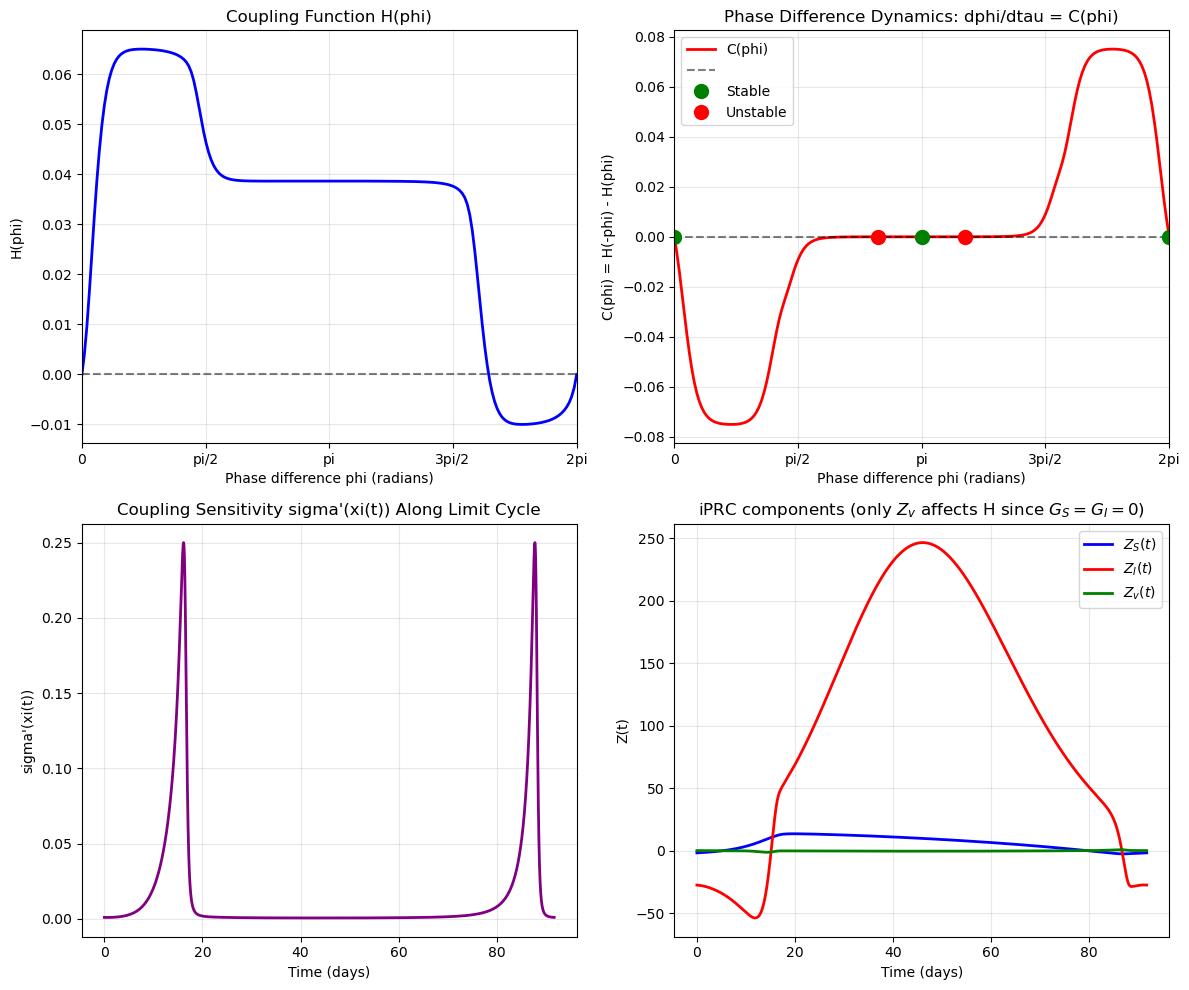


SUMMARY
Period T = 91.7060 days
omega = 2*pi/T = 0.068514 rad/day
phi is in radians; C'(phi) is therefore a rate in day^-1

Coupling function H(phi) computed
Phase dynamics: dphi/dtau = H(-phi) - H(phi) = C(phi)

Phase-locked states occur where C(phi) = 0
  - Stable if C'(phi) < 0 (green dots)
  - Unstable if C'(phi) > 0 (red dots)


In [3]:
"""
Find the limit cycle (periodic orbit) for the uncoupled smooth SIRv system.

This script:
1. Integrates the system for a long time to reach the attractor
2. Detects the period using Poincare section crossings
3. Extracts one complete cycle gamma(t) = [S(t), I(t), v(t)]
4. Verifies periodicity
"""

import numpy as np
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt


# =============================================================================
# SYSTEM DEFINITION
# =============================================================================

def uncoupled_smooth_sirv(t, y, params):
    """
    Uncoupled smooth SIRv system (epsilon = 0)
    y = [S, I, v]
    """
    S, I, v = y
    alpha = params['alpha']
    beta = params['beta']
    gamma = params['gamma']
    eta = params['eta']
    theta = params['theta']
    kappa = params['kappa']
    rho = params['rho']

    dS = alpha*(1 - S - I) - beta*S*I - eta*v*S
    dI = -gamma*I + beta*S*I
    dv = -v + 1/(1 + np.exp(-kappa*(beta*I - rho - theta*(1 - 2*v))))

    return [dS, dI, dv]


# =============================================================================
# PARAMETERS
# =============================================================================

params = {
    'alpha': 0.01,
    'beta': 0.5,
    'gamma': 1/7,
    'eta': 1/7,
    'theta': 0.01,
    'kappa': 400,
    'rho': 0.01,
}

y0 = [0.49, 0.01, 0.01]  # Initial conditions [S0, I0, v0]


# =============================================================================
# STEP 1: INTEGRATE PAST TRANSIENTS
# =============================================================================

t_transient = 5000

sol_transient = solve_ivp(
    lambda t, y: uncoupled_smooth_sirv(t, y, params),
    [0, t_transient],
    y0,
    method='RK45',
    rtol=1e-10,
    atol=1e-12
)

y_after_transient = sol_transient.y[:, -1]
print(f"State after transients: S={y_after_transient[0]:.6f}, "
      f"I={y_after_transient[1]:.6f}, v={y_after_transient[2]:.6f}")


# =============================================================================
# STEP 2: FIND THE PERIOD
# =============================================================================

t_cycle_search = 2000
dt = 0.01
t_eval = np.arange(0, t_cycle_search, dt)

sol_search = solve_ivp(
    lambda t, y: uncoupled_smooth_sirv(t, y, params),
    [0, t_cycle_search],
    y_after_transient,
    method='RK45',
    t_eval=t_eval,
    rtol=1e-10,
    atol=1e-12
)

# Find peaks in I to determine period
I_data = sol_search.y[1, :]
peaks, _ = find_peaks(I_data, height=np.mean(I_data), distance=int(1/dt))

peak_times = sol_search.t[peaks]
periods = np.diff(peak_times)
T = np.mean(periods[-5:])  # Average of last 5 periods

print(f"Period T = {T:.6f} days")


# =============================================================================
# STEP 3: EXTRACT ONE COMPLETE CYCLE
# =============================================================================

# Start from a peak (phase = 0 at peak I)
start_idx = peaks[-2]
y_cycle_start = sol_search.y[:, start_idx]

# Integrate for exactly one period
n_points = 10000
t_cycle = np.linspace(0, T, n_points)

sol_cycle = solve_ivp(
    lambda t, y: uncoupled_smooth_sirv(t, y, params),
    [0, T],
    y_cycle_start,
    method='RK45',
    t_eval=t_cycle,
    rtol=1e-12,
    atol=1e-14
)


# =============================================================================
# STEP 4: STORE THE LIMIT CYCLE AS Gamma
# =============================================================================

class Gamma:
    """
    Container for the limit cycle gamma(t) = [S(t), I(t), v(t)]

    Usage:
        Gamma.t    - time array [0, T]
        Gamma.S    - S(t) along the cycle
        Gamma.I    - I(t) along the cycle
        Gamma.v    - v(t) along the cycle
        Gamma.T    - period
        Gamma.y    - full state array, shape (3, n_points)
    """
    t = sol_cycle.t
    S = sol_cycle.y[0, :]
    I = sol_cycle.y[1, :]
    v = sol_cycle.y[2, :]
    T = T
    y = sol_cycle.y  # [S, I, v] stacked


# =============================================================================
# COMPUTE THE JACOBIAN DF USING SYMPY
# =============================================================================

import sympy as sp

# Define symbolic variables
S_sym, I_sym, v_sym = sp.symbols('S I v')
alpha_sym, beta_sym, gamma_sym, eta_sym = sp.symbols('alpha beta gamma eta')
theta_sym, kappa_sym, rho_sym = sp.symbols('theta kappa rho')

# Define the vector field F = [F1, F2, F3]
F1 = alpha_sym*(1 - S_sym - I_sym) - beta_sym*S_sym*I_sym - eta_sym*v_sym*S_sym
F2 = -gamma_sym*I_sym + beta_sym*S_sym*I_sym
F3 = -v_sym + 1/(1 + sp.exp(-kappa_sym*(beta_sym*I_sym - rho_sym
                                        - theta_sym*(1 - 2*v_sym))))

F = sp.Matrix([F1, F2, F3])
state = sp.Matrix([S_sym, I_sym, v_sym])

# Compute Jacobian symbolically
DF_symbolic = F.jacobian(state)

# Convert to numerical function
param_symbols = (alpha_sym, beta_sym, gamma_sym, eta_sym,
                 theta_sym, kappa_sym, rho_sym)
all_symbols = (S_sym, I_sym, v_sym) + param_symbols

DF_func = sp.lambdify(all_symbols, DF_symbolic, modules='numpy')


def compute_DF(S, I, v, params):
    """
    Compute the Jacobian matrix DF at a point (S, I, v).

    Returns:
        DF : 3x3 numpy array
    """
    return np.array(DF_func(
        S, I, v,
        params['alpha'], params['beta'], params['gamma'], params['eta'],
        params['theta'], params['kappa'], params['rho']
    ))


# =============================================================================
# COMPUTE A(t) = DF(Gamma(t)) ALONG THE LIMIT CYCLE
# =============================================================================

n_points = len(Gamma.t)
A = np.zeros((n_points, 3, 3))

for i in range(n_points):
    A[i] = compute_DF(Gamma.S[i], Gamma.I[i], Gamma.v[i], params)


# =============================================================================
# COMPUTE Z(t) BY BACKWARD INTEGRATION OF THE ADJOINT EQUATION
# =============================================================================

from scipy.interpolate import interp1d

# -----------------------------------------------------------------------------
# Step 1: Compute gamma'(t) = F(gamma(t)) along the limit cycle
# -----------------------------------------------------------------------------

Gamma_dot = np.zeros((3, n_points))
for i in range(n_points):
    Gamma_dot[:, i] = uncoupled_smooth_sirv(Gamma.t[i], Gamma.y[:, i], params)

Gamma.S_dot = Gamma_dot[0, :]
Gamma.I_dot = Gamma_dot[1, :]
Gamma.v_dot = Gamma_dot[2, :]
Gamma.y_dot = Gamma_dot

print("Computed gamma'(t) = F(gamma(t)) along the limit cycle")


# -----------------------------------------------------------------------------
# Step 2: Create interpolation functions for A(t)
# -----------------------------------------------------------------------------

def A_periodic(t):
    """Return A(t mod T) for any t."""
    t_mod = np.mod(t, Gamma.T)
    idx = np.searchsorted(Gamma.t, t_mod)
    if idx >= len(Gamma.t):
        idx = len(Gamma.t) - 1
    return A[idx]


# For smoother interpolation
A_interp_base = interp1d(Gamma.t, A, axis=0, kind='linear',
                         fill_value='extrapolate')


def A_interp_periodic(t):
    """Periodic interpolation of A(t)."""
    t_mod = np.mod(t, Gamma.T)
    return A_interp_base(t_mod)


# -----------------------------------------------------------------------------
# Step 3: Define the adjoint equation dZ/dt = -A(t)^T @ Z
# -----------------------------------------------------------------------------

def adjoint_equation_reversed_periodic(s, Z, T):
    """
    Time-reversed adjoint equation for forward integration.

    s = total_time - t, so t = total_time - s
    But A(t) is periodic, so we use A(t mod T)

    dZ/ds = A(t)^T @ Z
    """
    A_t = A_interp_periodic(T - (s % T))  # Map back to [0, T] for A
    return A_t.T @ Z


# -----------------------------------------------------------------------------
# Step 4: Backward integration for MULTIPLE PERIODS
# -----------------------------------------------------------------------------

n_periods = 10
total_time = n_periods * Gamma.T

print(f"\nIntegrating adjoint equation for {n_periods} periods")
print(f"Total integration time: {total_time:.2f} days")

Z_initial = np.array([1.0, 1.0, 1.0])

n_points_total = n_points * n_periods
s_eval = np.linspace(0, total_time, n_points_total)

sol_adjoint = solve_ivp(
    lambda s, Z: adjoint_equation_reversed_periodic(s, Z, Gamma.T),
    [0, total_time],
    Z_initial,
    method='RK45',
    t_eval=s_eval,
    rtol=1e-10,
    atol=1e-12
)

print("Backward integration complete")
print(f"Solution shape: {sol_adjoint.y.shape}")

# Extract only the LAST period (converged to the periodic orbit)
last_period_start_idx = (n_periods - 1) * n_points
Z_raw = sol_adjoint.y[:, last_period_start_idx:]

# Flip to get Z(t) with t from 0 to T
Z_raw = Z_raw[:, ::-1]

# Make sure we have exactly n_points
if Z_raw.shape[1] != n_points:
    t_raw = np.linspace(0, Gamma.T, Z_raw.shape[1])
    Z_raw_interp = np.zeros((3, n_points))
    for i in range(3):
        Z_raw_interp[i, :] = np.interp(Gamma.t, t_raw, Z_raw[i, :])
    Z_raw = Z_raw_interp

print(f"Z_raw shape after extracting last period: {Z_raw.shape}")


# -----------------------------------------------------------------------------
# Step 5: Normalize so that Z(t) . gamma'(t) = 2*pi/T
# -----------------------------------------------------------------------------

omega = 2 * np.pi / Gamma.T  # angular frequency

Z_dot_Gamma_dot = np.sum(Z_raw * Gamma_dot, axis=0)

print(f"\nPeriod T = {Gamma.T:.6f}")
print(f"Angular frequency omega = 2*pi/T = {omega:.6f}")

print("\nBefore normalization:")
print(f"  Z . gamma' ranges from {Z_dot_Gamma_dot.min():.6e} "
      f"to {Z_dot_Gamma_dot.max():.6e}")

Z_normalized = Z_raw * omega / Z_dot_Gamma_dot

Z_dot_Gamma_dot_check = np.sum(Z_normalized * Gamma_dot, axis=0)
print("\nAfter normalization:")
print(f"  Z . gamma' should equal 2*pi/T = {omega:.6f}")
print(f"  Z . gamma' ranges from {Z_dot_Gamma_dot_check.min():.6f} "
      f"to {Z_dot_Gamma_dot_check.max():.6f}")


# -----------------------------------------------------------------------------
# Step 6: Verify periodicity: Z(T) should equal Z(0)
# -----------------------------------------------------------------------------

#print("\n" + "="*50)
#print("PERIODICITY CHECK")
#print("="*50)
#print(f"\nZ(0) = [{Z_normalized[0, 0]:.6f}, {Z_normalized[1, 0]:.6f}, "
 #     f"{Z_normalized[2, 0]:.6f}]")
#print(f"Z(T) = [{Z_normalized[0, -1]:.6f}, {Z_normalized[1, -1]:.6f}, "
 #     f"{Z_normalized[2, -1]:.6f}]")

Z_diff = Z_normalized[:, -1] - Z_normalized[:, 0]
#print(f"\nZ(T) - Z(0) = [{Z_diff[0]:.6e}, {Z_diff[1]:.6e}, {Z_diff[2]:.6e}]")
#print(f"|Z(T) - Z(0)| = {np.linalg.norm(Z_diff):.6e}")

#if np.linalg.norm(Z_diff) < 1e-3:
 #   print("Z is periodic (error < 1e-3)")
#else:
 #   print("Z is NOT periodic -- may need more periods!")


# -----------------------------------------------------------------------------
# Step 7: Store Z(t) in a clean container
# -----------------------------------------------------------------------------

class Z_solution:
    """
    Container for the adjoint solution Z(t) = [Z_S(t), Z_I(t), Z_v(t)]

    This is the infinitesimal Phase Response Curve (iPRC).

    Usage:
        Z.t    - time array [0, T]
        Z.S    - Z_S(t), sensitivity to perturbations in S
        Z.I    - Z_I(t), sensitivity to perturbations in I
        Z.v    - Z_v(t), sensitivity to perturbations in v
        Z.y    - full solution array, shape (3, n_points)
    """
    t = Gamma.t
    S = Z_normalized[0, :]
    I = Z_normalized[1, :]
    v = Z_normalized[2, :]
    y = Z_normalized
    T = Gamma.T


Z = Z_solution()


# =============================================================================
# COMPUTE THE COUPLING FUNCTION H(phi)
# =============================================================================

# -----------------------------------------------------------------------------
# Step 1: sigma'(xi(t)) along the limit cycle
# -----------------------------------------------------------------------------

def compute_sigma_prime_along_cycle(Gamma, params):
    """
    Compute sigma'(xi(t)) along the limit cycle, where:
        xi(t)      = kappa*(beta*I(t) - rho - theta*(1 - 2*v(t)))
        sigma(x)   = 1/(1 + exp(-x))
        sigma'(xi) = sigma(xi)*(1 - sigma(xi))

    Returns:
        sigma_prime : array of sigma'(xi(t)) at each time point
    """
    kappa = params['kappa']
    beta = params['beta']
    rho = params['rho']
    theta = params['theta']

    xi = kappa * (beta * Gamma.I - rho - theta * (1 - 2 * Gamma.v))

    sigma = 1 / (1 + np.exp(-xi))
    sigma_prime = sigma * (1 - sigma)

    return sigma_prime


sigma_prime = compute_sigma_prime_along_cycle(Gamma, params)

#print("Computed sigma'(xi(t)) along the limit cycle")
print(f"  sigma' ranges from {sigma_prime.min():.6e} to {sigma_prime.max():.6e}")


# -----------------------------------------------------------------------------
# Step 2: Periodic interpolation
# -----------------------------------------------------------------------------

from scipy.interpolate import interp1d


def make_periodic_interp(t, y, T):
    """
    Create interpolation function with periodic extension.

    For any query time t_q, it returns y(t_q mod T).
    """
    # Remove the last point to avoid duplicate at t=0 and t=T
    t_one_period = t[:-1]
    y_one_period = y[:-1]

    # Extend to cover [-T, 2T] for safe interpolation
    t_extended = np.concatenate([t_one_period - T, t_one_period,
                                 t_one_period + T])
    y_extended = np.concatenate([y_one_period, y_one_period, y_one_period])

    interp_func = interp1d(t_extended, y_extended, kind='cubic')

    def periodic_func(t_query):
        t_mod = np.mod(t_query, T)
        return interp_func(t_mod)

    return periodic_func


v_interp = make_periodic_interp(Gamma.t, Gamma.v, Gamma.T)

print("Created periodic interpolation for v(t)")


# -----------------------------------------------------------------------------
# Step 3: Compute H(phi) for a range of phi values
# -----------------------------------------------------------------------------

def compute_H(phi, Gamma, Z, sigma_prime, v_interp, params):
    """
    Compute the coupling function H(phi) using numerical integration.

    Social-only coupling: G_S = G_I = 0, so only Z_v contributes.

    phi is measured in RADIANS while gamma is parametrized by time, so the
    shifted trajectory is gamma(t + phi/omega) with omega = 2*pi/T.

    H(phi) = (1/T) * int_0^T Z_v(t) * (-2*kappa*theta) * sigma'(xi(t))
                              * (v(t) - v(t + phi/omega)) dt
    """
    kappa = params['kappa']
    theta = params['theta']
    T = Gamma.T
    omega = 2 * np.pi / T

    # v(t + phi/omega) at each time point
    v_shifted = v_interp(Gamma.t + phi/omega)

    integrand = Z.v * (-2) * kappa * theta * sigma_prime * (Gamma.v - v_shifted)

    H = np.trapz(integrand, Gamma.t) / T

    return H


# Compute H(phi) for phi in [0, 2*pi] (radians)
n_phi = 200
phi_values = np.linspace(0, 2*np.pi, n_phi)
H_values = np.zeros(n_phi)

for i, phi in enumerate(phi_values):
    H_values[i] = compute_H(phi, Gamma, Z, sigma_prime, v_interp, params)

print(f"\nComputed H(phi) at {n_phi} points")
print(f"  H ranges from {H_values.min():.6e} to {H_values.max():.6e}")


# -----------------------------------------------------------------------------
# Step 4: Store H(phi) in a container
# -----------------------------------------------------------------------------

class H_function:
    """
    Container for the coupling function H(phi).

    Usage:
        H.phi    - phi values in radians [0, 2*pi]
        H.theta  - identical to H.phi (kept so older plotting code still runs)
        H.values - H(phi) at each point
        H.T      - period of the limit cycle, in days
    """
    phi = phi_values
    theta = phi_values
    values = H_values
    T = Gamma.T


H = H_function()

H_interp = make_periodic_interp(H.phi, H.values, 2*np.pi)

print("\nH(phi) stored in H container")


# -----------------------------------------------------------------------------
# Step 5: Odd part C(phi) = H(-phi) - H(phi)
# -----------------------------------------------------------------------------

# For identical oscillators, phase difference evolves as:
# dphi/dtau = H(-phi) - H(phi) := C(phi)

C_values = np.zeros(n_phi)
for i, phi in enumerate(phi_values):
    H_minus_phi = compute_H(-phi, Gamma, Z, sigma_prime, v_interp, params)
    C_values[i] = H_minus_phi - H_values[i]

print("\nComputed C(phi) = H(-phi) - H(phi)")
print(f"  C ranges from {C_values.min():.6e} to {C_values.max():.6e}")


# -----------------------------------------------------------------------------
# Step 6: Find fixed points (phase-locked states)
# -----------------------------------------------------------------------------

# Fixed points occur where C(phi) = 0
# Stable if C'(phi) < 0, unstable if C'(phi) > 0

from scipy.interpolate import UnivariateSpline
from scipy.optimize import brentq

C_spline = UnivariateSpline(phi_values, C_values, s=0)
C_derivative = C_spline.derivative()

sign_changes = np.where(np.diff(np.sign(C_values)))[0]

print("\n" + "="*50)
print("PHASE-LOCKED STATES")
print("="*50)

for idx in sign_changes:
    phi_left = phi_values[idx]
    phi_right = phi_values[idx + 1]

    try:
        phi_zero = brentq(C_spline, phi_left, phi_right)
        C_prime_at_zero = C_derivative(phi_zero)
        stability = "STABLE" if C_prime_at_zero < 0 else "UNSTABLE"

        theta_zero = phi_zero

        print(f"\n  phi = {phi_zero:.4f} rad = {np.degrees(phi_zero):.2f} deg")
        print(f"    C'(phi) = {C_prime_at_zero:.6e} /day")
        print(f"    {stability}")
    except Exception:
        pass


# C'(0) and C'(pi): both are rates in day^-1 under this convention.
# C'(0) is read at phi = 2*pi because the spline is not periodic and its
# left endpoint is the less reliable one.
Cp_0 = float(C_derivative(2*np.pi))
Cp_pi = float(C_derivative(np.pi))
print("\n  C'(0)  = %+.6e /day" % Cp_0)
print("  C'(pi) = %+.6e /day" % Cp_pi)
print("  |C'(0)/C'(pi)| = %.1f" % abs(Cp_0/Cp_pi))


# -----------------------------------------------------------------------------
# Step 7: Plot everything
# -----------------------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Plot H(phi)
ax1 = axes[0, 0]
ax1.plot(H.theta, H.values, 'b-', linewidth=2)
ax1.axhline(y=0, color='k', linestyle='--', alpha=0.5)
ax1.set_xlabel('Phase difference phi (radians)')
ax1.set_ylabel('H(phi)')
ax1.set_title('Coupling Function H(phi)')
ax1.set_xlim([0, 2*np.pi])
ax1.set_xticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi])
ax1.set_xticklabels(['0', 'pi/2', 'pi', '3pi/2', '2pi'])
ax1.grid(True, alpha=0.3)

# Plot C(phi) = H(-phi) - H(phi)
ax2 = axes[0, 1]
theta_values = phi_values
ax2.plot(theta_values, C_values, 'r-', linewidth=2)
ax2.axhline(y=0, color='k', linestyle='--', alpha=0.5)
ax2.set_xlabel('Phase difference phi (radians)')
ax2.set_ylabel('C(phi) = H(-phi) - H(phi)')
ax2.set_title('Phase Difference Dynamics: dphi/dtau = C(phi)')
ax2.set_xlim([0, 2*np.pi])
ax2.set_xticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi])
ax2.set_xticklabels(['0', 'pi/2', 'pi', '3pi/2', '2pi'])
ax2.grid(True, alpha=0.3)

# Mark fixed points on C(phi)
for idx in sign_changes:
    try:
        phi_left = phi_values[idx]
        phi_right = phi_values[idx + 1]
        phi_zero = brentq(C_spline, phi_left, phi_right)
        theta_zero = phi_zero
        C_prime = C_derivative(phi_zero)
        color = 'go' if C_prime < 0 else 'ro'  # green = stable, red = unstable
        ax2.plot(theta_zero, 0, color, markersize=10)
    except Exception:
        pass

ax2.legend(['C(phi)', '', 'Stable', 'Unstable'], loc='best')

# Plot sigma'(xi(t)) to show when coupling is active
ax3 = axes[1, 0]
ax3.plot(Gamma.t, sigma_prime, 'purple', linewidth=2)
ax3.set_xlabel('Time (days)')
ax3.set_ylabel("sigma'(xi(t))")
ax3.set_title("Coupling Sensitivity sigma'(xi(t)) Along Limit Cycle")
ax3.grid(True, alpha=0.3)

# Plot all Z components
ax4 = axes[1, 1]
ax4.plot(Z.t, Z.S, 'b-', linewidth=2, label='$Z_S(t)$')
ax4.plot(Z.t, Z.I, 'r-', linewidth=2, label='$Z_I(t)$')
ax4.plot(Z.t, Z.v, 'g-', linewidth=2, label='$Z_v(t)$')
ax4.set_xlabel('Time (days)')
ax4.set_ylabel('Z(t)')
ax4.set_title('iPRC components (only $Z_v$ affects H since $G_S = G_I = 0$)')
ax4.grid(True, alpha=0.3)
ax4.legend()

plt.tight_layout()
plt.savefig('coupling_function_H.png', dpi=150)
plt.show()

print("\n" + "="*50)
print("SUMMARY")
print("="*50)
print(f"Period T = {Gamma.T:.4f} days")
print(f"omega = 2*pi/T = {2*np.pi/Gamma.T:.6f} rad/day")
print("phi is in radians; C'(phi) is therefore a rate in day^-1")
print("\nCoupling function H(phi) computed")
print("Phase dynamics: dphi/dtau = H(-phi) - H(phi) = C(phi)")
print("\nPhase-locked states occur where C(phi) = 0")
print("  - Stable if C'(phi) < 0 (green dots)")
print("  - Unstable if C'(phi) > 0 (red dots)")